# World model d'une balle rebondissante.

# Étape 1 : la balle passive

## Accroche
Quand un humain laisse tomber une balle, son cerveau ne calcule pas la trajectoire avec des équations.
Il a un « modèle » intuitif de la façon dont la balle va se comporter : c'est son modèle du monde.
C'est exactement l'idée des world models en IA : apprendre à un agent à se construire une représentation
interne de son environnement, pour imaginer ce qui va se passer avant que cela n'arrive.

## Pourquoi c'est utile
Un agent qui apprend uniquement par essais et erreurs a besoin d'énormément d'interactions avec son
environnement, ce qui est lent, coûteux, voire dangereux dans le monde réel. Un humain sait qu'une chute
du haut d'une falaise serait fatale sans avoir besoin d'essayer. Un world model permet de la même façon
d'apprendre et de planifier « en imagination ».

## Le projet
On construit progressivement un world model dans le style proposé par LeCun (2022) :
1. **Balle passive** (ce notebook) : prédire le mouvement d'une balle à partir de ses positions passées.
2. **Balle pilotable** : ajouter des actions et planifier pour amener la balle vers une cible.
3. **JEPA** : travailler directement à partir d'images, en prédisant dans un espace latent appris.

## Ce notebook
**Objectif :** apprendre à un petit réseau de neurones à prédire le déplacement suivant de la balle
à partir de ses 3 dernières positions.

**Critère de réussite :**
- loin des murs, le réseau fait aussi bien qu'une simple extrapolation linéaire ;
- autour des rebonds, il fait nettement mieux ;
- en rollout, il suit la vraie trajectoire en passant plusieurs rebonds, sur des trajectoires jamais vues.

## 1. Formalisme

### 1.1 Le world model selon LeCun (2022)
LeCun décompose un world model en deux fonctions apprises :

$$
s(t) = \mathrm{Enc}\big(x(t)\big), \qquad
\hat{s}(t+1) = \mathrm{Pred}\big(s(t),\ a(t),\ z(t)\big)
$$

- $x(t)$ : l'**observation** à l'instant $t$ (une image, des mesures de capteurs…) ;
- $s(t)$ : l'**état** du monde, une représentation abstraite de l'observation ;
- $a(t)$ : l'**action** de l'agent ;
- $z(t)$ : une **variable latente** qui représente ce qui est imprévisible (plusieurs futurs possibles).

L'encodeur choisit *ce qu'il faut représenter*, le prédicteur apprend *comment cela évolue*.
Dans une JEPA, la prédiction se fait dans l'espace des états, et non dans celui des observations.

### 1.2 Notre cas : la balle passive
Dans ce notebook, on simplifie au maximum :
- **observation** : la position de la balle, $p(t) \in [0,1]^2$ ;
- **pas d'action** : on ne fait qu'observer la balle ;
- **pas de variable latente** : le mouvement est déterministe ;
- **pas d'encodeur appris** : la position est déjà une représentation simple.

Une seule position ne suffit pas à connaître l'état de la balle, car elle ne donne pas sa vitesse.
On définit donc l'état comme l'historique des $k$ dernières positions :

$$
s(t) = \big(p(t-k+1),\ \dots,\ p(t)\big), \qquad k = 3
$$

### 1.3 Ce que le réseau apprend
Plutôt que de prédire la position suivante, le réseau $f_\theta$ prédit le **déplacement** :

$$
\widehat{\Delta p}(t) = f_\theta\big(s(t)\big), \qquad
\hat{p}(t+1) = p(t) + \widehat{\Delta p}(t)
$$

Prédire le déplacement empêche le réseau d'obtenir une erreur faible en recopiant simplement
la dernière position. Il est entraîné en minimisant l'erreur quadratique entre le déplacement
prédit et le vrai déplacement, tous deux normalisés.

### 1.4 Le rollout : imaginer la suite
Pour prédire plusieurs pas, on réinjecte les prédictions du modèle dans son propre état :

$$
\hat{s}(t+1) = \big(p(t-k+2),\ \dots,\ p(t),\ \hat{p}(t+1)\big)
$$

Le modèle simule alors la trajectoire « dans sa tête », sans utiliser le simulateur.
C'est ce qui en fait un world model, et c'est aussi là que ses erreurs s'accumulent.

### 1.5 Les étapes suivantes
- **Étape 2** : on ajoute une action $a(t)$, une poussée donnée à la balle, pour pouvoir planifier.
- **Étape 3** : l'observation devient une image ; on apprend alors $\mathrm{Enc}$ et on prédit
  dans l'espace latent, comme dans une JEPA.

*Remarque.* On paramètre ici $f_\theta$ par une prédiction directe. Une alternative est d'apprendre
une énergie $E_\theta(s, \hat{p})$ et de prédire par minimisation (approche EBM). La JEPA réconcilie
les deux : elle définit une énergie comme l'écart entre l'état prédit et l'état réellement encodé.

Je vais modeliser ici une balle qui se déplace dans une boîte 2D ( par exemple [0,1]X[0,1]) à vitesse constante entre deux rebonds.
Pour la modélisation on se basera uniquement sur l'état observé $x(t) = (p_x(t), p_y(t)) \in R$. On ne donne jamais la vitesse explicitement au modèle.

**Contexte** :  une fenêtre glissante des k dernières positions  ctx $(k) = (x(1):x(k))$

**Futur candidat** : $\hat{x}(k+1) \in R²$

**Energie à apprendre** : $E_{\theta}(ctx(k), \hat{x}(k+1) \in R$

faible si $\hat{x}(k+1)$ est cohérent avec la trajectoire physique (vitesse constante, ou rebond correct si le contexte montre qu'on approche d'un bord), élevé sinon.

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
SEED = 42
rng = np.random.default_rng(SEED)
box=(0.0, 1.0)
pos = rng.uniform(box[0] + 0.1, box[1] - 0.1, size=2)
print(pos)

[0.71916484 0.45110275]


In [ ]:
def simulate_bouncing_ball(rng, n_steps=200, step_size=0.03, box=(0.0, 1.0)):
    """
    Simule une balle qui se déplace à vitesse constante dans une boîte carrée
    et rebondit élastiquement sur les murs.

    Paramètres
    ----------
    rng : np.random.Generator
        Générateur aléatoire partagé, pour des trajectoires différentes mais reproductibles.
    n_steps : int
        Nombre de positions dans la trajectoire.
    step_size : float
        Distance parcourue par la balle à chaque pas.
    box : tuple
        Limites (min, max) de la boîte, identiques sur les deux axes.

    sorties
    -------
    positions : np.ndarray de forme (n_steps, 2)
        Positions successives de la balle.
    bounces : np.ndarray de forme (n_steps,), booléens
        bounces[t] vaut True si un rebond a eu lieu entre les pas t-1 et t.
    """
    low, high = box
    # Un pas plus grand que la boîte casserait la logique de réflexion ci-dessous
    assert step_size < (high - low), "Le pas doit être plus petit que la boîte."

    # Position de départ aléatoire, avec une marge pour ne pas commencer contre un mur
    margin = 0.1 * (high - low) # marge
    pos = rng.uniform(low + margin, high - margin, size=2) # depart haha

    # Direction aléatoire ; la norme du déplacement reste fixée à step_size
    angle = rng.uniform(0.0, 2.0 * np.pi)
    velocity = step_size * np.array([np.cos(angle), np.sin(angle)]) # v = (v.cos(angle), v.sin(angle))

    positions = np.zeros((n_steps, 2)) # matrice de taille n_steps x 2
    bounces = np.zeros(n_steps, dtype=bool) # vecteur colonne de taille n_steps de 0 pour pas de rebons et 1 pour rebond
    positions[0] = pos # initialisation des positions

    for t in range(1, n_steps): # boucle sur le nombre de déplacement
        pos = pos + velocity  # déplacement en ligne droite ( équation horaire pipo)

        # On vérifie chaque axe séparément (d = 0 pour x, d = 1 pour y)
        for d in range(2):         #boucle sur les coordonnées de pos
            if pos[d] < low:                    # la balle a dépassé le mur bas/gauche
                pos[d] = 2 * low - pos[d]       # on la réfléchit à l'intérieur de la boîte
                velocity[d] *= -1               # sa vitesse s'inverse sur cet axe
                bounces[t] = True
            elif pos[d] > high:                 # la balle a dépassé le mur haut/droit
                pos[d] = 2 * high - pos[d]
                velocity[d] *= -1
                bounces[t] = True

        positions[t] = pos

    return positions, bounces

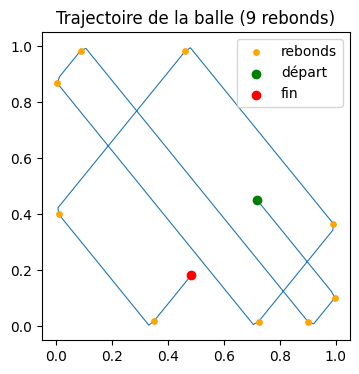

In [ ]:
rng = np.random.default_rng(42)

positions, bounces = simulate_bouncing_ball(rng, n_steps=200, step_size=0.03)

plt.figure(figsize=(4, 4))
plt.plot(positions[:, 0], positions[:, 1], lw=0.8)
plt.scatter(*positions[bounces].T, c="orange", s=15, label="rebonds", zorder=4)
plt.scatter(*positions[0], c="green", label="départ", zorder=5)
plt.scatter(*positions[-1], c="red", label="fin", zorder=5)
plt.xlim(-0.05, 1.05); plt.ylim(-0.05, 1.05)
plt.gca().set_aspect("equal")
plt.legend(); plt.title(f"Trajectoire de la balle ({bounces.sum()} rebonds)")
plt.show()

In [ ]:
positions, bounces

(array([[0.71916484, 0.45110275],
        [0.73808318, 0.42781979],
        [0.75700153, 0.40453683],
        [0.77591987, 0.38125387],
        [0.79483822, 0.35797091],
        [0.81375656, 0.33468795],
        [0.83267491, 0.31140499],
        [0.85159325, 0.28812203],
        [0.8705116 , 0.26483907],
        [0.88942994, 0.24155611],
        [0.90834828, 0.21827315],
        [0.92726663, 0.19499019],
        [0.94618497, 0.17170723],
        [0.96510332, 0.14842427],
        [0.98402166, 0.12514131],
        [0.99705999, 0.10185835],
        [0.97814165, 0.07857539],
        [0.9592233 , 0.05529243],
        [0.94030496, 0.03200947],
        [0.92138662, 0.00872651],
        [0.90246827, 0.01455645],
        [0.88354993, 0.03783941],
        [0.86463158, 0.06112237],
        [0.84571324, 0.08440534],
        [0.82679489, 0.1076883 ],
        [0.80787655, 0.13097126],
        [0.7889582 , 0.15425422],
        [0.77003986, 0.17753718],
        [0.75112151, 0.20082014],
        [0.732

In [ ]:
def make_examples(positions, bounces, k=3):
    """
    Transforme une trajectoire en exemples (contexte, déplacement suivant).

    Pour chaque instant t :
    - contexte : positions p(t-k+1), ..., p(t), aplaties en un vecteur de taille 2k ;
    - cible : déplacement p(t+1) - p(t) ;
    - near_bounce : True si un rebond a lieu entre p(t-k+1) et p(t+1).
    """
    X, Y, near_bounce = [], [], []
    for t in range(k - 1, len(positions) - 1):
        context = positions[t - k + 1 : t + 1]          # forme (k, 2)
        target = positions[t + 1] - positions[t]        # forme (2,)

        # bounces[j] indique un rebond entre p(j-1) et p(j) :
        # on regarde tous les pas couverts par le contexte et la cible
        bounce_nearby = bounces[t - k + 2 : t + 2].any()

        X.append(context.flatten())
        Y.append(target)
        near_bounce.append(bounce_nearby)

    return np.array(X), np.array(Y), np.array(near_bounce)

In [ ]:
K = 3              # taille du contexte
N_TRAJ = 500       # nombre de trajectoires
N_STEPS = 200      # positions par trajectoire
STEP_SIZE = 0.03   # déplacement par pas

rng = np.random.default_rng(SEED)
trajectories = [simulate_bouncing_ball(rng, N_STEPS, STEP_SIZE) for _ in range(N_TRAJ)]

# Séparation PAR TRAJECTOIRE : 80 % entraînement, 10 % validation, 10 % test
indices = rng.permutation(N_TRAJ)
n_train, n_val = int(0.8 * N_TRAJ), int(0.1 * N_TRAJ)
split_indices = {
    "train": indices[:n_train],
    "val": indices[n_train : n_train + n_val],
    "test": indices[n_train + n_val :],
}

def build_split(traj_indices):
    """Construit les exemples de toutes les trajectoires d'un split."""
    parts = [make_examples(*trajectories[i], k=K) for i in traj_indices]
    X = np.concatenate([p[0] for p in parts])
    Y = np.concatenate([p[1] for p in parts])
    near_bounce = np.concatenate([p[2] for p in parts])
    return X, Y, near_bounce

data = {name: build_split(idx) for name, idx in split_indices.items()}

for name, (X, Y, nb) in data.items():
    print(f"{name:5s} : X {X.shape}, Y {Y.shape}, exemples près d'un rebond : {nb.mean():.1%}")

train : X (78800, 6), Y (78800, 2), exemples près d'un rebond : 11.3%
val   : X (9850, 6), Y (9850, 2), exemples près d'un rebond : 11.2%
test  : X (9850, 6), Y (9850, 2), exemples près d'un rebond : 11.1%


In [ ]:
X_train, Y_train, _ = data["train"]

x_mean, x_std = X_train.mean(axis=0), X_train.std(axis=0)
y_mean, y_std = Y_train.mean(axis=0), Y_train.std(axis=0)

def normalize(X, Y):
    return (X - x_mean) / x_std, (Y - y_mean) / y_std

In [ ]:
X_test, Y_test, nb_test = data["test"]

# Dernier déplacement observé : p(t) - p(t-1), soit les deux dernières positions du contexte
last_disp = X_test[:, -2:] - X_test[:, -4:-2]
errors = np.linalg.norm(last_disp - Y_test, axis=1)

print(f"Erreur loin des rebonds  : {errors[~nb_test].mean():.2e}  (doit être ~0)")
print(f"Erreur près des rebonds  : {errors[nb_test].mean():.2e}  (doit être nettement plus grande)")

Erreur loin des rebonds  : 3.05e-18  (doit être ~0)
Erreur près des rebonds  : 1.61e-02  (doit être nettement plus grande)


In [ ]:
import torch.nn as nn

class DynamicsMLP(nn.Module):
    """
    Prédicteur de dynamique : à partir des K dernières positions,
    prédit le déplacement suivant de la balle.
    """

    def __init__(self, k, x_mean, x_std, y_mean, y_std, hidden=64):
        super().__init__()
        self.k = k
        self.net = nn.Sequential(
            nn.Linear(2 * k, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, 2),
        )
        # Statistiques de normalisation, enregistrées comme "buffers" :
        # elles sont sauvegardées avec le modèle, mais ne sont pas entraînées
        self.register_buffer("x_mean", torch.as_tensor(x_mean, dtype=torch.float32))
        self.register_buffer("x_std", torch.as_tensor(x_std, dtype=torch.float32))
        self.register_buffer("y_mean", torch.as_tensor(y_mean, dtype=torch.float32))
        self.register_buffer("y_std", torch.as_tensor(y_std, dtype=torch.float32))

    def forward(self, x_norm):
        """Entrée et sortie NORMALISÉES. Utilisé pendant l'entraînement."""
        return self.net(x_norm)

    @torch.no_grad()
    def predict_next_position(self, context):
        """
        Prédit la position suivante, en vraies unités.
        context : tableau numpy de forme (K, 2).
        """
        x = torch.as_tensor(context.flatten(), dtype=torch.float32)
        x_norm = (x - self.x_mean) / self.x_std          # 1. normaliser l'entrée
        delta_norm = self.forward(x_norm)                # 2. prédire en échelle normalisée
        delta = delta_norm * self.y_std + self.y_mean    # 3. dénormaliser la sortie
        return context[-1] + delta.numpy()               # 4. position suivante

In [ ]:
model = DynamicsMLP(K, x_mean, x_std, y_mean, y_std)

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def to_tensors(split):
    """Normalise un split et le convertit en tenseurs PyTorch."""
    X, Y, _ = data[split]
    X_norm, Y_norm = normalize(X, Y)
    return (torch.tensor(X_norm, dtype=torch.float32),
            torch.tensor(Y_norm, dtype=torch.float32))

X_train_t, Y_train_t = to_tensors("train")
X_val_t, Y_val_t = to_tensors("val")

# Paquets de 256 exemples, mélangés à chaque passage sur les données
train_loader = DataLoader(TensorDataset(X_train_t, Y_train_t), batch_size=256, shuffle=True)

In [ ]:
model = DynamicsMLP(K, x_mean, x_std, y_mean, y_std)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

N_EPOCHS = 50
history = {"train": [], "val": []}

for epoch in range(N_EPOCHS):
    # --- Entraînement ---
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        pred = model(xb)                 # prédiction (échelle normalisée)
        loss = loss_fn(pred, yb)         # erreur par rapport au vrai déplacement

        optimizer.zero_grad()            # on efface les gradients du batch précédent
        loss.backward()                  # on calcule les nouveaux gradients
        optimizer.step()                 # on met à jour les poids

        total_loss += loss.item() * len(xb)
    train_loss = total_loss / len(X_train_t)

    # --- Validation ---
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t), Y_val_t).item()

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if epoch % 5 == 0 or epoch == N_EPOCHS - 1:
        print(f"Époque {epoch:3d} | train {train_loss:.4f} | val {val_loss:.4f}")

Époque   0 | train 0.4088 | val 0.0806
Époque   5 | train 0.0612 | val 0.0614
Époque  10 | train 0.0485 | val 0.0484
Époque  15 | train 0.0382 | val 0.0374
Époque  20 | train 0.0303 | val 0.0317
Époque  25 | train 0.0240 | val 0.0243
Époque  30 | train 0.0184 | val 0.0192
Époque  35 | train 0.0148 | val 0.0139
Époque  40 | train 0.0123 | val 0.0118
Époque  45 | train 0.0101 | val 0.0095
Époque  49 | train 0.0085 | val 0.0096


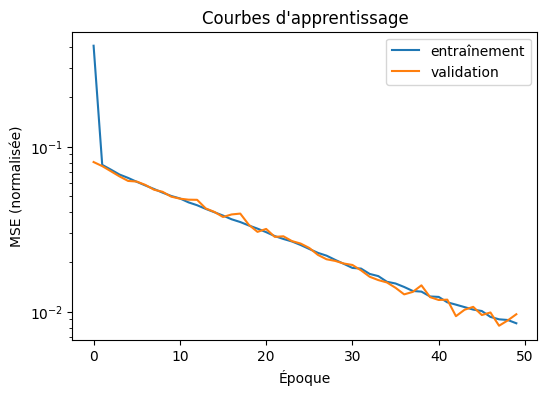

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="entraînement")
plt.plot(history["val"], label="validation")
plt.yscale("log")
plt.xlabel("Époque"); plt.ylabel("MSE (normalisée)")
plt.legend(); plt.title("Courbes d'apprentissage")
plt.show()

### Interprétation des courbes d'apprentissage

**Première époque.** La loss d'entraînement de l'époque 0 (≈ 0,4) est élevée car elle fait la moyenne
de tous les batches de l'époque, y compris les premiers, calculés avec des poids aléatoires. La loss
de validation est mesurée à la fin de l'époque, sur le modèle déjà amélioré : elle démarre donc
directement autour de 0,08. Dès la première époque, le réseau a appris l'essentiel du comportement
de la balle : poursuivre son déplacement en ligne droite.

**Descente régulière.** De l'époque 1 à 49, les deux courbes passent de ≈ 0,08 à ≈ 0,009, en suivant
une droite en échelle logarithmique : l'erreur diminue d'environ 4 à 5 % par époque. Cette phase plus
lente correspond probablement à l'apprentissage des rebonds, qui demande au réseau de construire
une fonction non linéaire plus fine (inverser la vitesse lorsque la balle atteint un mur).
Cette hypothèse sera vérifiée par l'évaluation séparée loin des murs et autour des rebonds.

**Généralisation.** Les courbes d'entraînement et de validation se superposent : le modèle fait
aussi bien sur des trajectoires jamais vues que sur celles d'entraînement. Il n'y a pas de
surapprentissage, ce qui indique que le réseau apprend une règle générale plutôt que de mémoriser
des trajectoires. Les petites fluctuations de la validation sont normales : elle est mesurée une seule
fois par époque, alors que la loss d'entraînement est moyennée sur plusieurs centaines de batches.

**Convergence.** À l'époque 49, les deux courbes diminuent encore : l'entraînement n'a pas atteint
de plateau, et le modèle peut encore progresser avec davantage d'époques.

**Limite.** Une loss basse ne suffit pas à conclure que le modèle a appris la dynamique. Il faut la
comparer à l'extrapolation linéaire, en particulier autour des rebonds, et vérifier la qualité des
prédictions sur plusieurs pas (rollouts).

Je vais donc :

1- Relancer l’entraînement avec plus d’époques, jusqu’à la convergence.

2- Ajouter la ligne de la baseline au graphique.

3- Passer à l’évaluation détaillée sur le test : erreur loin des murs, erreur autour des rebonds, puis rollouts.


In [ ]:
torch.manual_seed(SEED)  # même initialisation à chaque exécution

model = DynamicsMLP(K, x_mean, x_std, y_mean, y_std)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

N_EPOCHS = 300
# Le taux d'apprentissage décroît en douceur de 1e-3 à presque 0 au fil des époques
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)

history = {"train": [], "val": []}

for epoch in range(N_EPOCHS):
    # --- Entraînement ---
    model.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
    scheduler.step()  # mise à jour du taux d'apprentissage, une fois par époque
    train_loss = total_loss / len(X_train_t)

    # --- Validation ---
    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t), Y_val_t).item()

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    if epoch % 25 == 0 or epoch == N_EPOCHS - 1:
        print(f"Époque {epoch:3d} | train {train_loss:.5f} | val {val_loss:.5f}")

Époque   0 | train 0.42213 | val 0.07890
Époque  25 | train 0.03174 | val 0.03157
Époque  50 | train 0.01314 | val 0.01152
Époque  75 | train 0.00519 | val 0.00663
Époque 100 | train 0.00173 | val 0.00228
Époque 125 | train 0.00107 | val 0.00079
Époque 150 | train 0.00059 | val 0.00068
Époque 175 | train 0.00041 | val 0.00065
Époque 200 | train 0.00030 | val 0.00025
Époque 225 | train 0.00021 | val 0.00021
Époque 250 | train 0.00017 | val 0.00019
Époque 275 | train 0.00014 | val 0.00015
Époque 299 | train 0.00013 | val 0.00015


MSE normalisée de l'extrapolation linéaire : 0.06966


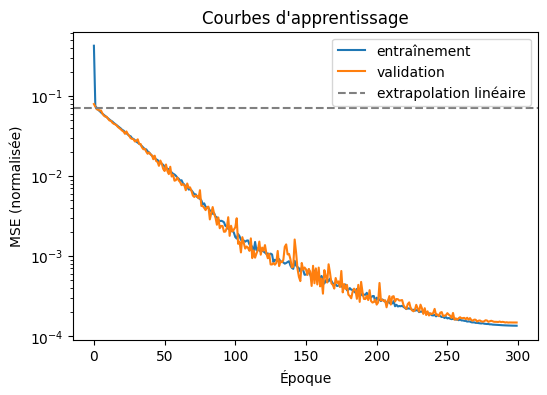

In [ ]:
# calcule la MSE de l’extrapolation linéaire sur la validation,
# dans la même échelle normalisée que le réseau, pour que la comparaison soit directe
X_val, Y_val, _ = data["val"]
last_disp_val = X_val[:, -2:] - X_val[:, -4:-2]
baseline_mse = np.mean(((last_disp_val - Y_val) / y_std) ** 2)
print(f"MSE normalisée de l'extrapolation linéaire : {baseline_mse:.5f}")

plt.figure(figsize=(6, 4))
plt.plot(history["train"], label="entraînement")
plt.plot(history["val"], label="validation")
plt.axhline(baseline_mse, color="gray", linestyle="--", label="extrapolation linéaire")
plt.yscale("log")
plt.xlabel("Époque"); plt.ylabel("MSE (normalisée)")
plt.legend(); plt.title("Courbes d'apprentissage")
plt.show()

### Interprétation des courbes d'apprentissage (300 époques)

Le modèle est entraîné pendant 300 époques avec Adam, et un taux d'apprentissage qui décroît
de $10^{-3}$ à environ 0 selon un schéma en cosinus (`CosineAnnealingLR`).

**Comparaison à la baseline.** L'extrapolation linéaire, qui prolonge le dernier déplacement observé,
obtient une MSE normalisée de 0,0697 sur la validation (ligne grise). Le réseau passe sous ce niveau
dès les premières époques et termine à 0,00015, soit une erreur environ 460 fois plus faible.
Comme l'extrapolation linéaire est exacte loin des murs, cet écart provient principalement des
situations de rebond, ce que l'évaluation séparée sur le test me permettra de confirmer ou d'infirmer.

**Dynamique d'apprentissage.** La loss diminue d'abord de façon régulière, en suivant une droite en
échelle logarithmique, puis ralentit progressivement. Entre les époques 100 et 175, la validation
présente davantage de fluctuations : le taux d'apprentissage y est encore élevé, et chaque mise à jour
fait légèrement osciller le modèle. Ces oscillations disparaissent à mesure que le taux diminue.

**Convergence.** Les courbes atteignent un plateau à partir de l'époque 250 environ. Ce plateau
s'explique en partie par le scheduler : en fin d'entraînement, le taux d'apprentissage est presque nul car t tends vers T
et les poids n'évoluent presque plus. Il ne prouve donc pas que le modèle a atteint sa capacité maximale.

**Généralisation.** Les courbes d'entraînement et de validation restent superposées tout au long de
l'entraînement (0,00013 contre 0,00015 à la fin). Il n'y a pas de surapprentissage : le modèle fait
aussi bien sur des trajectoires jamais vues que sur les trajectoires d'entraînement.

3. Évaluation détaillée sur le test

3.a. Prédiction à un pas, loin des murs et autour des rebonds

In [ ]:
def predict_displacements(model, X):
    """Prédit les déplacements (en vraies unités) pour un tableau de contextes X de forme (n, 2K)."""
    model.eval()
    with torch.no_grad():
        x = torch.tensor(X, dtype=torch.float32)
        x_norm = (x - model.x_mean) / model.x_std
        delta = model(x_norm) * model.y_std + model.y_mean
    return delta.numpy()

In [ ]:
# comparaison en vraies unités
X_test, Y_test, nb_test = data["test"]

pred_model = predict_displacements(model, X_test)
pred_linear = X_test[:, -2:] - X_test[:, -4:-2]

err_model = np.linalg.norm(pred_model - Y_test, axis=1)
err_linear = np.linalg.norm(pred_linear - Y_test, axis=1)

print(f"{'':25s} {'Réseau':>10s} {'Extrap. lin.':>14s}")
print(f"{'Loin des rebonds':25s} {err_model[~nb_test].mean():10.2e} {err_linear[~nb_test].mean():14.2e}")
print(f"{'Autour des rebonds':25s} {err_model[nb_test].mean():10.2e} {err_linear[nb_test].mean():14.2e}")
print(f"{'Tous les exemples':25s} {err_model.mean():10.2e} {err_linear.mean():14.2e}")

                              Réseau   Extrap. lin.
Loin des rebonds            1.99e-04       3.05e-18
Autour des rebonds          6.71e-04       1.61e-02
Tous les exemples           2.51e-04       1.79e-03


### Interprétation de l'erreur à un pas sur le test

On mesure l'erreur moyenne (distance euclidienne) entre le déplacement prédit et le vrai déplacement,
sur les trajectoires de test, en séparant les exemples loin des murs et ceux situés autour d'un rebond
(environ 11 % des exemples).

| | Réseau | Extrapolation linéaire |
|---|---|---|
| Loin des rebonds | 1,99e-04 | 3,05e-18 |
| Autour des rebonds | 6,71e-04 | 1,61e-02 |
| Tous les exemples | 2,51e-04 | 1,79e-03 |

**Loin des murs**, l'extrapolation linéaire est exacte, puisque la balle se déplace en ligne droite.
Le réseau ne peut pas faire mieux, mais son erreur reste très faible : environ 0,7 % de la longueur
d'un pas.

**Autour des rebonds**, le réseau est environ 24 fois plus précis que l'extrapolation linéaire, qui
ignore l'existence des murs. Le réseau a donc appris la règle de réflexion sur les murs uniquement à
partir des positions observées, sans jamais recevoir d'information explicite sur les rebonds.

**Les rebonds restent la principale source d'erreur** : l'erreur du réseau y est environ 3 fois plus
élevée que loin des murs.

3.b. Rollouts : imaginer plusieurs pas

In [ ]:
def rollout_model(model, init_context, n_steps):
    """Le modèle imagine n_steps positions à partir d'un contexte initial de K positions réelles."""
    context = init_context.copy()
    predicted = []
    for _ in range(n_steps):
        next_pos = model.predict_next_position(context)
        predicted.append(next_pos)
        context = np.vstack([context[1:], next_pos])  # on fait glisser la fenêtre
    return np.array(predicted)

def rollout_linear(init_context, n_steps):
    """Baseline : la balle continue avec son dernier déplacement, sans tenir compte des murs."""
    last_disp = init_context[-1] - init_context[-2]
    steps = np.arange(1, n_steps + 1)[:, None]
    return init_context[-1] + steps * last_disp

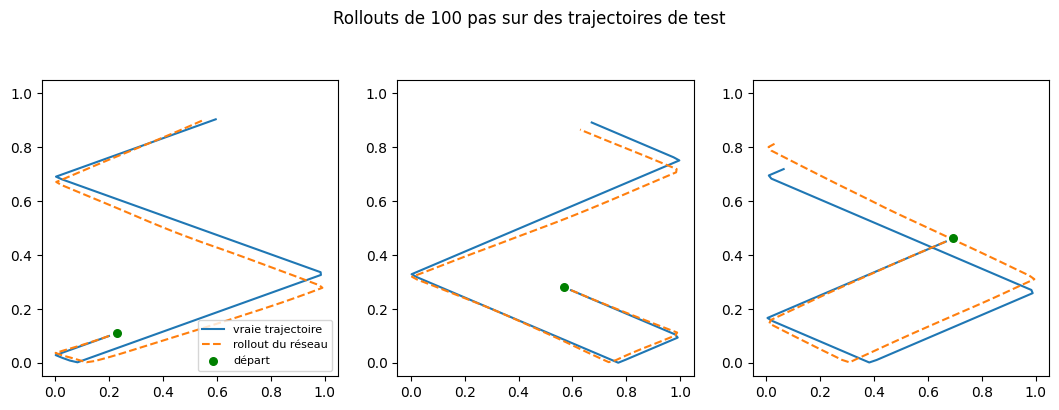

In [ ]:
N_ROLL = 100 # nombre de rollout

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, i in zip(axes, split_indices["test"][:3]):
    positions, _ = trajectories[i]
    true_future = positions[K : K + N_ROLL]
    pred_future = rollout_model(model, positions[:K], N_ROLL)

    ax.plot(*true_future.T, label="vraie trajectoire", lw=1.5)
    ax.plot(*pred_future.T, "--", label="rollout du réseau", lw=1.5)
    ax.scatter(*positions[K - 1], c="green", s=30, zorder=5, label="départ")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); ax.set_aspect("equal")
axes[0].legend(fontsize=8)
plt.suptitle(f"Rollouts de {N_ROLL} pas sur des trajectoires de test")
plt.show()

### Interprétation des rollouts

On initialise le modèle avec les 3 premières positions réelles de trajectoires de test, puis il prédit
100 pas en réutilisant ses propres prédictions.

**Le modèle a appris la règle des rebonds.** Sur les trois trajectoires, le rollout rebondit sur le bon
mur et dans la bonne direction, et enchaîne 3 à 4 rebonds sans erreur qualitative. La séquence de
rebonds de la vraie trajectoire est reproduite, et le rollout termine à proximité de la position réelle.

**L'erreur se crée principalement aux rebonds.** Entre deux rebonds, le rollout est parallèle à la vraie
trajectoire : la direction et la vitesse de la balle sont bien conservées. L'écart apparaît lors des
rebonds, où le point d'impact est légèrement décalé, puis il se maintient et se propage aux rebonds
suivants. Cela explique la croissance progressive de l'erreur avec l'horizon.

**Les coins sont le cas le plus difficile.** Lorsque la balle rebondit sur deux murs presque
simultanément (trajectoire de gauche), le rollout peut inverser l'ordre des deux rebonds, ce qui crée
l'un des décalages les plus importants. Cette situation est rare dans les données d'entraînement et
combine deux inversions de vitesse successives.

Horizon  10 pas | réseau 0.005 | extrap. lin. 0.083
Horizon  50 pas | réseau 0.049 | extrap. lin. 1.810
Horizon 100 pas | réseau 0.111 | extrap. lin. 3.091


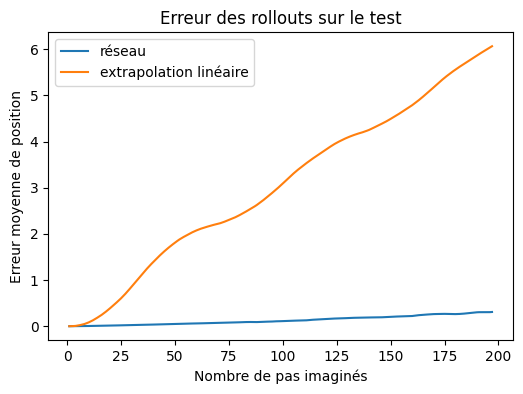

In [ ]:
n_roll = N_STEPS - K
err_roll_model, err_roll_linear = [], []

for i in split_indices["test"]:
    positions, _ = trajectories[i]
    true_future = positions[K:]
    err_roll_model.append(np.linalg.norm(rollout_model(model, positions[:K], n_roll) - true_future, axis=1))
    err_roll_linear.append(np.linalg.norm(rollout_linear(positions[:K], n_roll) - true_future, axis=1))

err_roll_model = np.mean(err_roll_model, axis=0)
err_roll_linear = np.mean(err_roll_linear, axis=0)

for h in [10, 50, 100]:
    print(f"Horizon {h:3d} pas | réseau {err_roll_model[h - 1]:.3f} | extrap. lin. {err_roll_linear[h - 1]:.3f}")

plt.figure(figsize=(6, 4))
plt.plot(np.arange(1, n_roll + 1), err_roll_model, label="réseau")
plt.plot(np.arange(1, n_roll + 1), err_roll_linear, label="extrapolation linéaire")
plt.xlabel("Nombre de pas imaginés"); plt.ylabel("Erreur moyenne de position")
plt.legend(); plt.title("Erreur des rollouts sur le test")
plt.show()

### Interprétation de l'erreur des rollouts

On mesure l'erreur moyenne de position en fonction du nombre de pas imaginés, sur toutes les
trajectoires de test. Le modèle et la baseline démarrent avec les 3 mêmes positions réelles, puis
prédisent la suite sans aucune nouvelle observation.

| Horizon | Réseau | Extrapolation linéaire |
|---|---|---|
| 10 pas | 0,005 | 0,083 |
| 50 pas | 0,049 | 1,810 |
| 100 pas | 0,111 | 3,091 |

**Le réseau reste précis sur un horizon long.** Après 10 pas, son erreur moyenne est d'environ
un sixième d'un pas de déplacement (0,03). Après 50 pas, elle atteint environ 5 % de la taille de
la boîte, et environ 11 % après 100 pas, alors que la balle a effectué en moyenne près de 4 rebonds.

**L'erreur croît progressivement.** Comme le modèle réutilise ses propres prédictions, chaque petite
erreur se propage aux pas suivants. Les rollouts individuels montrent que ces erreurs apparaissent
principalement lors des rebonds, où le point d'impact est légèrement décalé.

**La baseline n'est pas une référence exigeante sur plusieurs pas.** L'extrapolation linéaire ignore
les murs : dès le premier rebond, sa balle sort de la boîte et s'en éloigne indéfiniment, d'où des
erreurs supérieures à la taille de la boîte. Elle montre que le réseau a appris l'existence des murs,
mais elle ne permet pas de juger finement la qualité de ses rollouts. L'évaluation la plus exigeante
reste la prédiction à un pas autour des rebonds.

*Remarque : lien avec les modèles à énergie.*
Dans ce notebook aucune notion d'énergie n'a été spécifiée mais elle y est implicitement.
Le prédicteur appris définit implicitement l'énergie
$E(s, y) = \| \hat{p}(t+1) - y \|^2$, minimale lorsque la position candidate $y$ coïncide avec la
prédiction. Entraîner le modèle par MSE revient à attribuer une énergie faible à la vraie position
suivante. Dans ce cas particulier, le minimum de l'énergie est donné directement par le réseau, sans
optimisation. Une énergie plus générale devient nécessaire lorsque plusieurs futurs sont possibles,
ou lorsque la prédiction se fait dans un espace latent appris, comme dans une JEPA (étape 3).

Merci pour la lecture...